# Lista 5
Zuzanna Sosnowska

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score

### Zadanie 1

**Wprowadzenie do SVM:** Zaimplementuj SVM od podstaw dla danych, które są liniowo separowalne. Skup się na znalezieniu optymalnej
hiperpłaszczyzny, która maksymalizuje margines między klasami.

In [2]:
from scipy.optimize import minimize


class LinearSVM:
    def __init__(self):
        self.w = None
        self.b = None
        self.alphas = None
        self.fitted = False
        self.X = None
        self.y = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0
        self.alphas = np.zeros(n_samples)
        self.X = X
        self.y = y

        def _to_minimize(alphas):
            return 0.5 * (alphas @ (y.reshape(-1, 1) @ y.reshape(-1, 1).T * (X @ X.T)) @ alphas) - np.sum(alphas)

        constrains = {'type': 'eq', 'fun': lambda a: a @ y}
        bounds = [(0, None) for _ in range(n_samples)]
        result = minimize(
            fun=_to_minimize,
            x0=self.alphas,
            constraints=constrains,
            bounds=bounds
        )

        self.alphas = result.x
        self.w = np.sum((self.alphas * y).reshape(-1, 1) * X, axis=0)

        sv = np.where(self.alphas > 1e-6)[0][0]
        self.b = y[sv] - self.w @ X[sv]
        self.fitted = True

    def predict(self, X):
        return np.sign(X @ self.w + self.b)

    def plot(self, data=None):
        if not self.fitted:
            raise Exception("Not fitted")
        if data is None:
            X = self.X
        else:
            X = np.array(data)

        y_pred = self.predict(X)
        x_plot = np.linspace(min(X[:, 0]), max(X[:, 0]), 200)
        y_dec = -(self.w[0] * x_plot + self.b) / self.w[1]

        y_margin_pos = -(self.w[0] * x_plot + self.b - 1) / self.w[1]
        y_margin_neg = -(self.w[0] * x_plot + self.b + 1) / self.w[1]

        plt.scatter(X[:,0], X[:,1], c=y_pred, s=60)

        plt.plot(x_plot, y_dec, 'k-', label="Optymalna hiperpłaszczyzna")

        plt.plot(x_plot, y_margin_pos, 'k--', linewidth=1)
        plt.plot(x_plot, y_margin_neg, 'k--', linewidth=1)
        plt.fill_between(x_plot, y_margin_pos, y_margin_neg, color='k', alpha=0.2)

        plt.xlabel("X1")
        plt.ylabel("X2")
        plt.title("Klasyfikacja punktów z użyciem SVM")

        if data is None:
            sv_idx = np.where(self.alphas > 1e-6)[0]
            support_vectors = X[sv_idx]

            plt.scatter(support_vectors[:,0], support_vectors[:,1],
                        s=200, facecolors='none', edgecolors='k', linewidths=2,
                        label="Wektory nośne")
        plt.legend()
        plt.show()

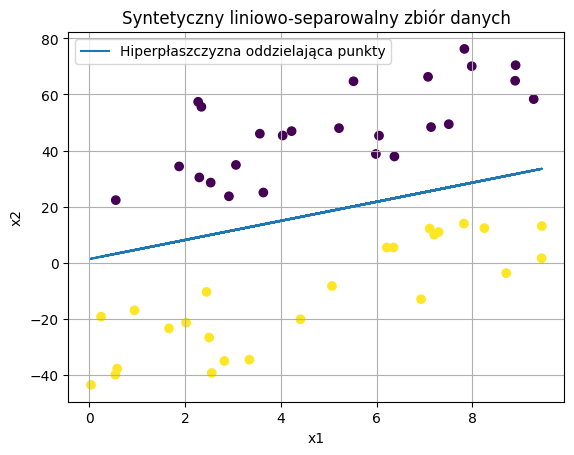

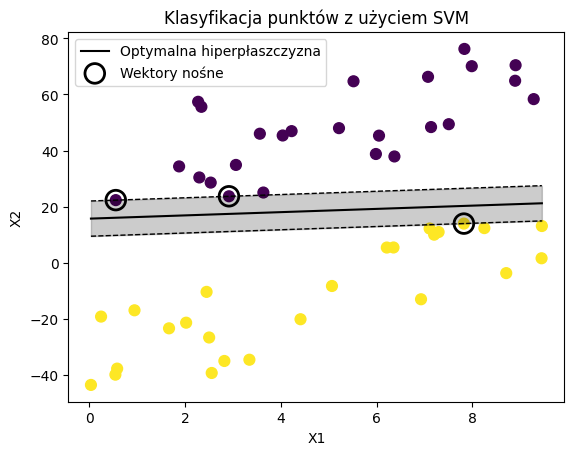

In [3]:
a = np.random.uniform(1, 4)
b = np.random.uniform(-5, 5)

n = 50
x1 = np.random.uniform(0, 10, n)
x2 = np.array([a * x1_i + b + 10 * np.random.uniform(1, 5) * (1 if np.random.random() < 0.5 else -1) for x1_i in x1])
y = np.array([1 if x2_i <= a * x1_i + b else -1 for x1_i, x2_i in zip(x1, x2)])

plt.scatter(x1, x2, c=y)
plt.plot(x1, a * x1 + b, label="Hiperpłaszczyzna oddzielająca punkty")
plt.title("Syntetyczny liniowo-separowalny zbiór danych")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()

X = np.array([[x1_i, x2_i] for x1_i, x2_i in zip(x1, x2)])

svm = LinearSVM()
svm.fit(X, y)

svm.plot()

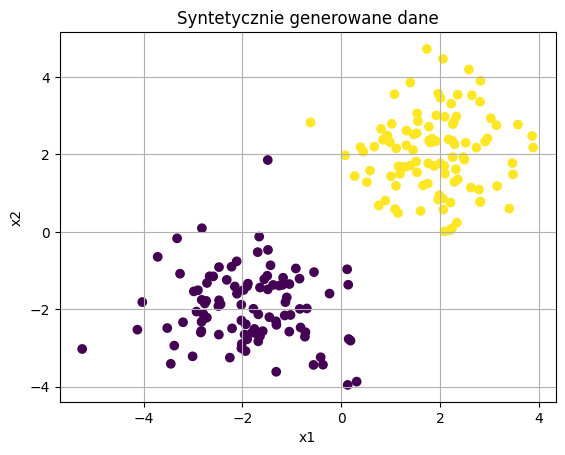

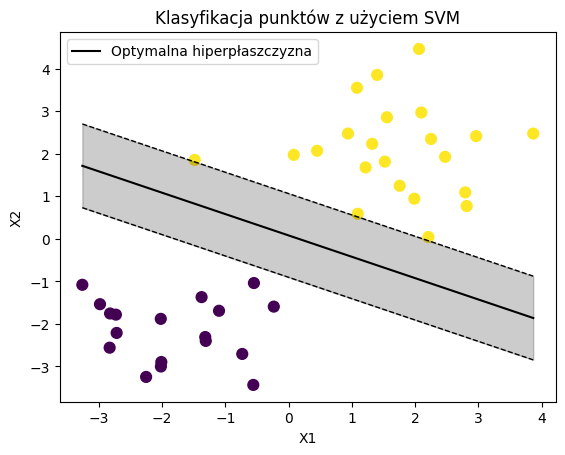

In [4]:
import numpy as np
from sklearn.model_selection import train_test_split


np.random.seed(42)

class1 = np.random.randn(100, 2) + np.array([2, 2])
class2 = np.random.randn(100, 2) + np.array([-2, -2])

X = np.vstack([class1, class2])
y = np.hstack([np.ones(100), -1 * np.ones(100)])

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Syntetycznie generowane dane")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

svm = LinearSVM()
svm.fit(X_train, y_train)

y_pred = svm.predict(X_test)

svm.plot(X_test)

### Zadanie 2

**Zastosowanie SVM z scikit-learn:** Wczytaj zbiór danych `Breast Cancer` z biblioteki `scikit-learn`. Podziel dane na zbiór treningowy i testowy. Zbuduj model SVM z jądrem liniowym (`kernel=’linear’`) i oceń jego wydajność.

In [5]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

In [6]:
breast_cancer_df = load_breast_cancer(as_frame=True).frame
y = breast_cancer_df["target"]
X = breast_cancer_df.drop("target", axis=1)

bc_X_train, bc_X_test, bc_y_train, bc_y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(bc_X_train)
X_test_scaled = scaler.transform(bc_X_test)

model = SVC(kernel="linear")
model.fit(X_train_scaled, bc_y_train)

prediction = model.predict(X_test_scaled)

accuracy = accuracy_score(prediction, bc_y_test)
precision = precision_score(prediction, bc_y_test)
recall = recall_score(prediction, bc_y_test)
score = model.score(X_test_scaled, bc_y_test)

pd.DataFrame({"accuracy": [accuracy], "precision": [precision], "recall": [recall], "score": [score]}, index=["linear SVM"])

,accuracy,precision,recall,score
linear SVM,0.973684,0.972222,0.985915,0.973684


### Zadanie 3

**Jądro (kernel trick):** Wygeneruj syntetyczny zbiór danych, który nie jest liniowo separowalny (np. dane w kształcie okręgów). Wytrenuj model SVM z jądrem Gaussa (`kernel=’rbf’`) i zwizualizuj granice decyzyjne. Porównaj wyniki z modelem SVM z jądrem liniowym i wyjaśnij, dlaczego jądro RBF jest w tym przypadku skuteczniejsze.

Dokładność dla SVM z jądrem liniowym: 0.485
Dokładność dla SVM z jądrem Gaussa: 0.965


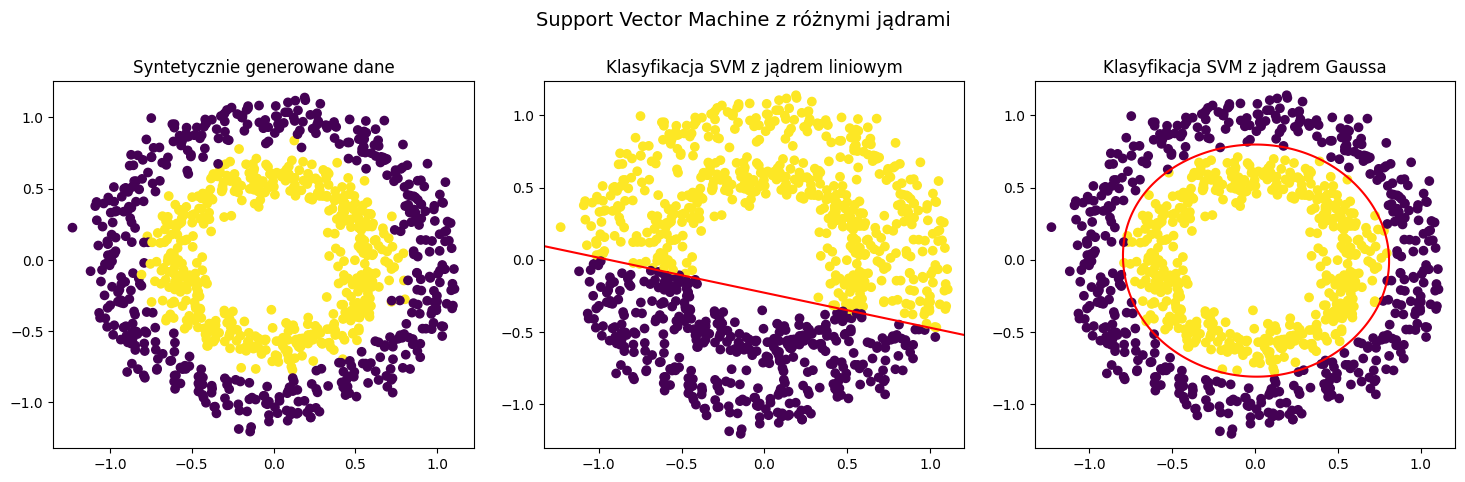

In [7]:
from sklearn.datasets import make_circles


X, y = make_circles(
    n_samples=1000,
    shuffle=True,
    noise=0.09,
    random_state=42,
    factor=0.6
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


svm_linear = SVC(kernel="linear")
svm_gaussian = SVC(kernel="rbf")

svm_linear.fit(X_train, y_train)
svm_gaussian.fit(X_train, y_train)

prediction1 = svm_linear.predict(X)
prediction2 = svm_gaussian.predict(X)

print("Dokładność dla SVM z jądrem liniowym:", svm_linear.score(X_test, y_test))
print("Dokładność dla SVM z jądrem Gaussa:", svm_gaussian.score(X_test, y_test))

x_min, x_max = X[:, 0].min() - 0.1, X[:, 0].max() + 0.1
y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

Z_linear = svm_linear.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z_gaussian = svm_gaussian.decision_function(np.c_[xx.ravel(), yy.ravel()])

Z_linear = Z_linear.reshape(xx.shape)
Z_gaussian = Z_gaussian.reshape(xx.shape)


fig, ax = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Support Vector Machine z różnymi jądrami", fontsize=14)
fig.tight_layout(pad=2)

ax[0].scatter(X[:, 0], X[:, 1], c=y)
ax[0].set_title("Syntetycznie generowane dane")

ax[1].scatter(X[:, 0], X[:, 1], c=prediction1)
ax[1].contour(xx, yy, Z_linear, levels=[0], colors="red")
ax[1].set_title("Klasyfikacja SVM z jądrem liniowym")

ax[2].scatter(X[:, 0], X[:, 1], c=prediction2)
ax[2].contour(xx, yy, Z_gaussian, levels=[0], colors="red")
ax[2].set_title("Klasyfikacja SVM z jądrem Gaussa")

plt.show()

### Zadanie 4

**Dostrajanie hiperparametrów SVM:** Dla modelu SVM na danych `Breast Cancer`, użyj `GridSearchCV` lub `RandomizedSearchCV` do optymalizacji hiperparametrów, takich jak parametr regularyzacji _C_ i gamma $\gamma$ dla jądra RBF. Porównaj wyniki z modelem o domyślnych parametrach.

In [8]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV


breast_cancer_df = load_breast_cancer(as_frame=True).frame
y = breast_cancer_df["target"]
X = breast_cancer_df.drop("target", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

default_model = SVC(kernel="rbf")
default_model.fit(X_train, y_train)

default_prediction = default_model.predict(X_test)

default_accuracy = accuracy_score(default_prediction, y_test)
default_precision = precision_score(default_prediction, y_test)
default_recall = recall_score(default_prediction, y_test)

params = {
    'C': np.arange(1, 1501, 100),
    'gamma': np.linspace(0.00001, 0.01, 30)
}

grid = GridSearchCV(
    SVC(kernel='rbf'),
    params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Optymalne hiperparametry dla metody GridSearchCV:", grid.best_params_)

grid_best_model = grid.best_estimator_
y_pred_grid = grid_best_model.predict(X_test)

grid_accuracy = accuracy_score(y_test, y_pred_grid)
grid_precision = precision_score(y_test, y_pred_grid)
grid_recall = recall_score(y_test, y_pred_grid)

randomized = RandomizedSearchCV(
    SVC(kernel='rbf'),
    param_distributions=params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

randomized.fit(X_train, y_train)

print("Optymalne hiperparametry dla metody RandomizedSearchCV:", randomized.best_params_)

randomized_best_model = randomized.best_estimator_
y_pred_randomized = randomized_best_model.predict(X_test)

randomized_accuracy = accuracy_score(y_test, y_pred_randomized)
randomized_precision = precision_score(y_test, y_pred_randomized)
randomized_recall = recall_score(y_test, y_pred_randomized)

result_df = pd.DataFrame({"Accuracy": [default_accuracy, grid_accuracy, randomized_accuracy],
                          "Precision": [default_precision, grid_precision, randomized_precision],
                          "Recall": [default_recall, grid_recall, randomized_recall]}, index=["Default", "Grid", "Randomized"])
result_dfndomizedSearchCV: {'gamma': np.float64(1e-05), 'C': np.int64(101)}

Optymalne hiperparametry dla metody GridSearchCV: {'C': np.int64(501), 'gamma': np.float64(1e-05)}
Optymalne hiperparametry dla metody RandomizedSearchCV: {'gamma': np.float64(1e-05), 'C': np.int64(101)}


,Accuracy,Precision,Recall
Default,0.947368,1.000000,0.922078
Grid,0.956140,0.958333,0.971831
Randomized,0.956140,0.945946,0.985915


### Zadanie 5

**Porównanie XGBoost i LightGBM:** Zainstaluj i użyj bibliotek `xgboost` i `lightgbm`. Wytrenuj oba modele na danych `Breast Cancer` i porównaj ich czas treningu oraz dokładność. Zidentyfikuj, który z nich jest szybszy i dlaczego.

In [9]:
import time
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


breast_cancer_df = load_breast_cancer(as_frame=True).frame
y = breast_cancer_df["target"]
X = breast_cancer_df.drop("target", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


start_xgb = time.time()

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

xgb_time = time.time() - start_xgb
xgb_pred = xgb_model.predict(X_test)
xgb_acc = accuracy_score(y_test, xgb_pred)
xgb_prec = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)


start_lgbm = time.time()

lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
)

lgbm_model.fit(X_train, y_train)

lgbm_time = time.time() - start_lgbm
lgbm_pred = lgbm_model.predict(X_test)
lgbm_acc = accuracy_score(y_test, lgbm_pred)
lgbm_prec = precision_score(y_test, lgbm_pred)
lgbm_recall = recall_score(y_test, lgbm_pred)

result_df = pd.DataFrame({"Time":[xgb_time, lgbm_time],
                          "Accuracy": [xgb_acc, lgbm_acc],
                          "Precision": [xgb_prec, lgbm_prec],
                          "Recall": [xgb_recall, lgbm_recall]},
                         index=["XGB", "LGBM"]
                        )
result_df

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 286, number of negative: 169
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000281 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4548
[LightGBM] [Info] Number of data points in the train set: 455, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.628571 -> initscore=0.526093
[LightGBM] [Info] Start training from score 0.526093
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

,Time,Accuracy,Precision,Recall
XGB,0.303058,0.956140,0.958333,0.971831
LGBM,0.436256,0.964912,0.958904,0.985915


Na zbiorze Breast Cancer modele `XGBoost` i `LightGBM` osiągnęły bardzo zbliżoną dokładność, przy czym `LightGBM` minimalnie przewyższył `XGBoost` pod względem jakości predykcji. Z kolei czas treningu okazał się krótszy dla `XGBoost`.

### Zadanie 6

**Walidacja krzyżowa (Cross-validation):** Dla wybranego modelu (np. `XGBoost`) przeprowadź walidację krzyżową (`KFold` lub `StratifiedKFold`) w celu uzyskania bardziej rzetelnej oceny jego wydajności. Omów, dlaczego walidacja krzyżowa jest lepsza niż jednorazowy podział na zbiór treningowy i testowy.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_score


breast_cancer_df = load_breast_cancer(as_frame=True).frame
y = breast_cancer_df["target"]
X = breast_cancer_df.drop("target", axis=1)


model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss"
)

cv = StratifiedKFold(n_splits=30, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')

print("Wyniki walidacji krzyżowej (accuracy):", scores)
print("Średnia dokładność:", np.mean(scores))
print("Odchylenie standardowe:", np.std(scores))

Wyniki walidacji krzyżowej (accuracy): [0.94736842 1.         0.94736842 0.89473684 1.         1.
 1.         1.         0.94736842 0.94736842 0.84210526 0.89473684
 0.94736842 0.94736842 0.94736842 0.94736842 0.94736842 1.
 1.         1.         1.         1.         0.94736842 0.94736842
 1.         0.94736842 0.84210526 1.         0.94736842 1.        ]
Średnia dokładność: 0.9596491228070173
Odchylenie standardowe: 0.04441750491639357


Walidacja krzyżowa dostarcza bardziej wiarygodnej oceny jakości modelu niż pojedynczy podział danych, ponieważ testuje model na wielu różnych konfiguracjach zbiorów, co zmniejsza wariancję wyniku i pozwala lepiej ocenić zdolność modelu do generalizacji. W eksperymencie z XGBoost wyniki uzyskane metodą `StratifiedKFold` były stabilne i spójne, co potwierdza dobrą jakość modelu.